Train: (1257, 8, 8, 1) | Test: (540, 8, 8, 1)

Model              | Layers |   Params | Train Acc | Test Acc | Test Loss | Errors | Time(s)
--------------------------------------------------------------------------------------------
Simple CNN         |      7 |    35914 |    1.0000 |   0.9685 |    0.1151 |     17 |    22.3
ResNet-style CNN   |     27 |   152138 |    1.0000 |   0.9907 |    0.0305 |      5 |    43.4

Classification report - Simple CNN
              precision    recall  f1-score   support

           0      1.000     0.963     0.981        54
           1      0.917     1.000     0.957        55
           2      0.981     1.000     0.991        53
           3      1.000     0.982     0.991        55
           4      0.964     1.000     0.982        54
           5      0.964     0.982     0.973        55
           6      1.000     0.981     0.991        54
           7      0.915     1.000     0.956        54
           8      0.977     0.827     0.896        52
    

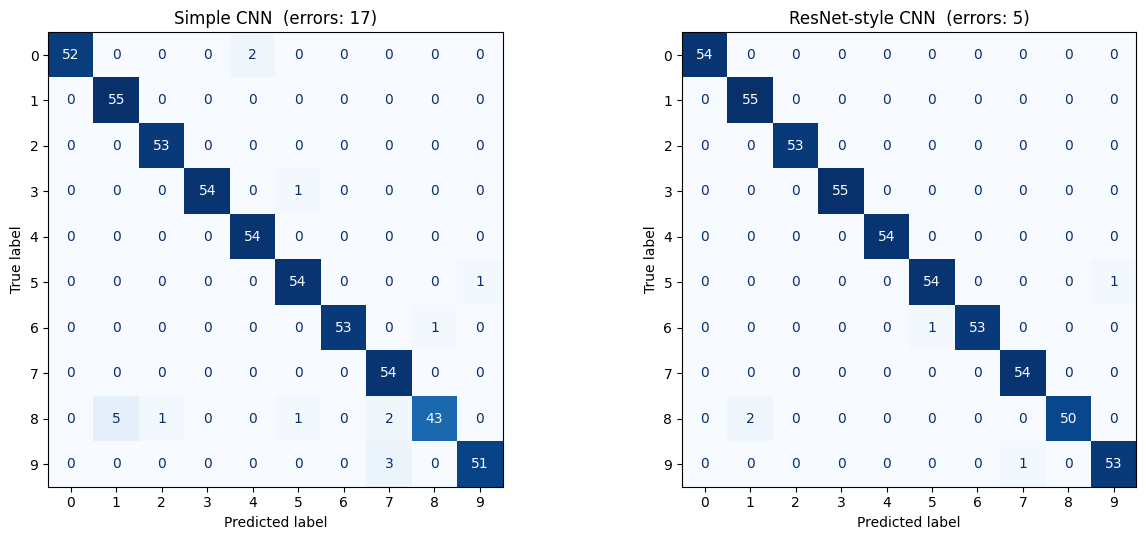

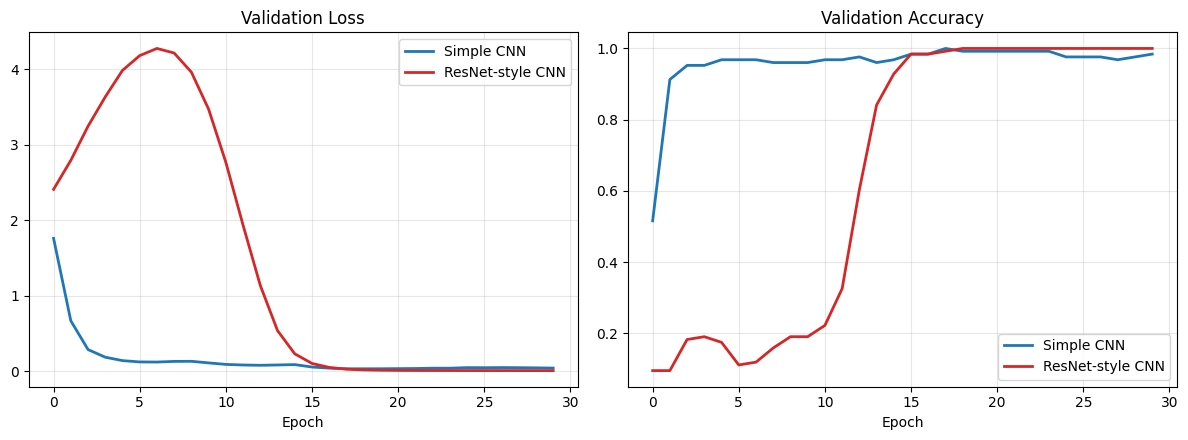


Misclassified (true -> predicted) - Simple CNN: [(9, 7), (5, 9), (3, 5), (8, 1), (8, 1), (6, 8), (8, 5), (0, 4), (9, 7), (8, 1), (9, 7), (0, 4), (8, 1), (8, 2), (8, 7), (8, 7), (8, 1)]

Misclassified (true -> predicted) - ResNet-style CNN: [(5, 9), (8, 1), (6, 5), (9, 7), (8, 1)]

Saved confusion_matrices.png and training_curves.png


In [8]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# -----------------------------
# Dataset: sklearn Digits (1797 images, 8x8 grayscale, 10 classes)
# -----------------------------
digits = load_digits()
X = digits.images.astype("float32") / 16.0        # pixel values 0-16 -> 0-1
X = X[..., np.newaxis]                            # shape (1797, 8, 8, 1)
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# -----------------------------
# Task 1: Two CNN models
# -----------------------------
def build_simple_cnn():
    """Simple CNN: 2 convolution blocks + dense classifier (no skip connections)."""
    return models.Sequential([
        layers.Input(shape=(8, 8, 1)),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ], name="Simple_CNN")

def residual_block(x, filters):
    """Two conv layers plus a skip connection (the core idea of ResNet)."""
    shortcut = x
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    if shortcut.shape[-1] != filters:                       # match channels for the addition
        shortcut = layers.Conv2D(filters, 1, padding="same")(shortcut)
    x = layers.Add()([x, shortcut])                         # skip connection
    return layers.Activation("relu")(x)

def build_resnet_style():
    """Mini ResNet-style CNN: residual blocks + global average pooling."""
    inputs = layers.Input(shape=(8, 8, 1))
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = residual_block(x, 32)
    x = layers.MaxPooling2D(2)(x)
    x = residual_block(x, 64)
    x = residual_block(x, 64)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return models.Model(inputs, outputs, name="ResNet_Style_CNN")

# -----------------------------
# Task 2: Train both models on the same data with the same settings
# -----------------------------
EPOCHS = 30
builders = {"Simple CNN": build_simple_cnn, "ResNet-style CNN": build_resnet_style}
results, histories, predictions = {}, {}, {}

for name, builder in builders.items():
    tf.keras.utils.set_random_seed(42)
    model = builder()
    model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    start = time.time()
    h = model.fit(X_train, y_train, epochs=EPOCHS, batch_size=32,
                  validation_split=0.1, verbose=0)
    train_time = time.time() - start

    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

    histories[name] = h.history
    predictions[name] = y_pred
    results[name] = dict(params=model.count_params(), layers=len(model.layers),
                         train_acc=h.history["accuracy"][-1], test_acc=test_acc,
                         test_loss=test_loss, time=train_time,
                         errors=int(np.sum(y_pred != y_test)))

# -----------------------------
# Task 3: Compare accuracy, complexity, confusion matrix, classification report
# -----------------------------
print(f"\n{'Model':<18} | {'Layers':>6} | {'Params':>8} | {'Train Acc':>9} | {'Test Acc':>8} | {'Test Loss':>9} | {'Errors':>6} | {'Time(s)':>7}")
print("-" * 92)
for name, r in results.items():
    print(f"{name:<18} | {r['layers']:>6} | {r['params']:>8} | {r['train_acc']:>9.4f} | "
          f"{r['test_acc']:>8.4f} | {r['test_loss']:>9.4f} | {r['errors']:>6} | {r['time']:>7.1f}")

for name, y_pred in predictions.items():
    print(f"\nClassification report - {name}")
    print(classification_report(y_test, y_pred, digits=3))

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}  (errors: {results[name]['errors']})")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=200)
plt.show()

# Training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = {"Simple CNN": "#1f77b4", "ResNet-style CNN": "#d62728"}
for name, h in histories.items():
    axes[0].plot(h["val_loss"], label=name, color=colors[name], linewidth=2)
    axes[1].plot(h["val_accuracy"], label=name, color=colors[name], linewidth=2)
axes[0].set_title("Validation Loss"); axes[1].set_title("Validation Accuracy")
for a in axes:
    a.set_xlabel("Epoch"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("training_curves.png", dpi=200)
plt.show()

# Misclassified samples (true -> predicted)
for name, y_pred in predictions.items():
    wrong = [(int(t), int(p)) for t, p in zip(y_test, y_pred) if t != p]
    print(f"\nMisclassified (true -> predicted) - {name}: {wrong}")

print("\nSaved confusion_matrices.png and training_curves.png")